# Curve curation walkthrough: convective wind × real estate

**Start here.** This notebook shows how the `convective_wind_real_estate` curves are built: which evidence they
use, how the EF tornado scale's damage descriptions become a damage ratio, why straight-line wind starts at 96 mph,
and which choices are judgment.

The companion [`01_runtime_curve_walkthrough.ipynb`](01_runtime_curve_walkthrough.ipynb) reads the artifact and
calls the curves the way Hazard would.

Status: **noncanonical proposal** (model v0.1 / docs r1). The cell documents in `docs/cells/convective_wind_real_estate/`
are the source of truth; this notebook only reads them.

In [1]:
from pathlib import Path
import json
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "docs/cells").is_dir() and (p / "scripts/reference_helpers").is_dir():
            return p
    raise RuntimeError("Run this notebook from inside the Damage_Modeling repository.")


ROOT = find_repo_root()
CELL_ID = "convective_wind_real_estate"
PROP = ROOT / "docs/cells" / CELL_ID / "proposed"
ARTIFACT_PATH = PROP / "convective_wind_real_estate__model_v0_1__docs_r1__curve_artifact.json"
REG = "convective_wind_real_estate__model_v0_1__docs_r1"  # tag of the cell registers (source, claims, tiers, decisions)
OUT = ROOT / "notebooks/convective_wind/real_estate/outputs"
OUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "scripts/reference_helpers"))

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

ART = json.loads(ARTIFACT_PATH.read_text())
# Replacement cost new from the Hazard reference profiles r1 (Q3 2025 Dallas prices). Illustration only:
# the artifacts withhold scenario dollars until the consumer qualifies each building value.
BUDGETS_USD = {"RE_RES_SFD_1S_SLAB": 405_000, "RE_IND_WAREHOUSE": 11_000_000, "RE_COM_OFFICE_3S_SLAB": 10_800_000}
NAMES = {"RE_RES_SFD_1S_SLAB": "House", "RE_IND_WAREHOUSE": "Warehouse", "RE_COM_OFFICE_3S_SLAB": "Office",
         "RE_COM_LOWRISE": "Retail (unbound)"}


def table(name: str) -> pd.DataFrame:
    return pd.read_csv(PROP / name)


def save(fig, name: str) -> None:
    fig.savefig(OUT / name, dpi=110, bbox_inches="tight", metadata={"Software": None})


def decision_log(path: Path) -> pd.DataFrame:
    """Decision-log rows: ID, whether JL decided it, and the decision text (shortened)."""
    rows = []
    for line in path.read_text().splitlines():
        if not line.startswith("| D-"):
            continue
        cells = [c.strip() for c in line.strip().strip("|").split(" | ")]
        text = re.sub(r"\*\*", "", cells[1])
        rows.append({"id": cells[0], "status": "JL decided" if "JL decided" in cells[1] else "proposed",
                      "decision": text if len(text) <= 240 else text[:240] + " …"})
    return pd.DataFrame(rows)


print("artifact:", ARTIFACT_PATH.relative_to(ROOT))
print(ART["cell_id"], "|", ART["semantic_damage_model_version"], "|", ART["damage_code_id"],
      "| promotion:", ART["promotion_status"], "| canonical:", ART["canonical_runtime_artifact"])

import derive_convective_wind_real_estate_ef_curves as derive

artifact: docs/cells/convective_wind_real_estate/proposed/convective_wind_real_estate__model_v0_1__docs_r1__curve_artifact.json
convective_wind_real_estate | model v0.1 | CONVECTIVE_WIND_REAL_ESTATE_EF_SCREENING_V0_1 | promotion: proposed | canonical: False


## 1. What the cell is

Two pathways on one failure unit (the building structure), for the three Hazard reference buildings:

- `straight_line_convective`: thunderstorm straight-line wind (downburst, gust front, derecho);
- `tornado_direct_hit`: a tornado passing over the building.

Both read a 3-second gust at 10 m in mph, each in its own field. The y-axis is repair cost ÷ structure
replacement cost new.

In [2]:
identity = pd.DataFrame([
    {"field": "cell", "value": ART["cell_id"]},
    {"field": "damage code", "value": ART["damage_code_id"]},
    {"field": "model / docs", "value": f'{ART["semantic_damage_model_version"]} / {ART["documentation_revision"]}'},
    {"field": "lifecycle / promotion", "value": f'{ART["lifecycle_state"]} / {ART["promotion_status"]}'},
    {"field": "canonical runtime artifact", "value": ART["canonical_runtime_artifact"]},
    {"field": "model grade", "value": ART["model_grade"]},
])
display(identity)
units = pd.DataFrame([{k: u.get(k) for k in ("id", "treatment", "denominator")} for u in ART["failure_units"]])
display(units)
pathways = pd.DataFrame([{
    "pathway": p["pathway_id"],
    "axis field": p["hazard_axis"]["preferred_input_field"],
    "unit": p["hazard_axis"]["unit"],
    "valid range": p["hazard_axis"]["valid_range"],
    "selectors": ", ".join(s["field"] for s in p["selector_logic"] if s.get("required")),
    "conditioners": ", ".join(c["field"] for c in p["conditioner_logic"]) or "-",
    "records": len(p["curve_records"]),
} for p in ART["pathways"]])
display(pathways)

,field,value
0,cell,convective_wind_real_estate
1,damage code,CONVECTIVE_WIND_REAL_ESTATE_EF_SCREENING_V0_1
2,model / docs,model v0.1 / docs r1
3,lifecycle / promotion,scaffold / proposed
4,canonical runtime artifact,False
5,model grade,screening_expert_elicited_damage_degrees_priced_by_damage_state


,id,treatment,denominator
0,CWRE_BUILDING_STRUCTURE,primary_nonzero,"structure replacement cost new of the same reference building (no land, contents, site works or depreciation)"
1,CWRE_BUILDING_CONTENTS,withheld,contents value (deferred)


,pathway,axis field,unit,valid range,selectors,conditioners,records
0,straight_line_convective,convective_gust_3s_10m_mph,mph,"[0.0, 255.0]",reference_building_id,-,3
1,tornado_direct_hit,tornado_gust_3s_10m_mph,mph,"[0.0, 255.0]",reference_building_id,-,3


## 2. Buildings and EF damage indicators

Each reference building is matched to the EF scale's damage indicator for its construction type.

In [3]:
pw = ART["pathways"][0]
display(pd.DataFrame([{"building": NAMES[b], "selector": b, "Hazard profile": prof,
                       "EF indicator": pw["ef_damage_indicators"][b]["di"],
                       "EF DI number": pw["ef_damage_indicators"][b]["di_number"]}
                      for b, prof in pw["reference_profile_binding"].items()]))

,building,selector,Hazard profile,EF indicator,EF DI number
0,House,RE_RES_SFD_1S_SLAB,re_house_1s_wood_slab,FR12,2
1,Warehouse,RE_IND_WAREHOUSE,re_warehouse_1s_steel_slab,MBS,21
2,Office,RE_COM_OFFICE_3S_SLAB,re_office_3s_slab,LRB,17


## 3. Evidence register

What each source is allowed to do is in the register's `permitted_inference` / `prohibited_inference` columns.

In [4]:
src = table(f"SOURCE_REGISTER_{REG}.csv")
src["citation"] = src["citation"].str.slice(0, 110)
display(src[["source_id", "citation", "source_role", "evidence_tier", "decision"]])

,source_id,citation,source_role,evidence_tier,decision
0,CWRE-S001,"Wind Science and Engineering Center, Texas Tech University. A Recommendation for an Enhanced Fujita Scale (EF-",curve_data_carrier;method_definition,T3_engineering_proxy_or_adjacent_empirical,adopt_with_limits
1,CWRE-S002,"NOAA Storm Prediction Center. The Enhanced Fujita Scale (EF Scale): damage indicator pages 2 (FR12), 17 (LRB)",curve_data_carrier;independent_verification,T3_engineering_proxy_or_adjacent_empirical,adopt_with_limits
2,CWRE-S003,FEMA. Hazus 7.0 Hurricane Model Technical Manual (June 2025).,cost_mapping,T3_engineering_proxy_or_adjacent_empirical,adopt_with_limits
3,CWRE-S004,"Hazard reference profiles r1 (real-estate CONUS reference candidates), aamani-ai/Hazard_Modeling.",selector_archetype;value_basis,T4_context,adopt
4,CWRE-S005,Hazard convective-wind hazard layer (strong wind [W] from ASCE 7-22 gust maps; tornado [T] from the SPC record,axis_bridge;check_input,T4_context,adopt
5,CWRE-S006,"FEMA National Risk Index, December 2025 edition, county building expected annual loss for strong wind and torn",benchmark_check,T3_engineering_proxy_or_adjacent_empirical,adopt_with_limits
6,CWRE-S007,Damage_Modeling repository precedents: strong_wind_solar model v1.0 thresholded demand curves; wind_tornado_wi,method_precedent,T4_context,adopt
7,CWRE-S008,Damage_Modeling consumer binding: substation convective-wind screening v1 (hurricane station response reused f,method_precedent,T4_context,context_only


## 4. The EF degrees of damage

For each building type the EF scale lists **degrees of damage** (from "threshold of visible damage" to total
destruction), each with an expected 3-second gust and a lower and upper bound, set by expert elicitation. The EF
scale gives no costs, so each degree is placed on FEMA's Hazus damage-state cost ladder
(Slight 2%, Moderate 10%, Extensive 50%, Complete 100%; 1% and 5% as in-between points). The `cost_basis` column
records why each degree sits where it does.

,reference_building_id,ef_damage_indicator,dod,damage_description,expected_mph,lower_bound_mph,upper_bound_mph,hazus_damage_state,cost_ratio
0,RE_RES_SFD_1S_SLAB,FR12,1,Threshold of visible damage,65,53,80,below_slight,0.01
1,RE_RES_SFD_1S_SLAB,FR12,2,"Loss of roof covering material (<20%), gutters and/or awning; loss of vinyl or metal siding",79,63,97,slight,0.02
2,RE_RES_SFD_1S_SLAB,FR12,3,Broken glass in doors and windows,96,79,114,slight_to_moderate,0.05
3,RE_RES_SFD_1S_SLAB,FR12,4,Uplift of roof deck and loss of significant roof covering material (>20%); collapse of chimney; garage doors collapse inward; failure of porch or carport,97,81,116,moderate,0.10
4,RE_RES_SFD_1S_SLAB,FR12,5,Entire house shifts off foundation,121,103,141,extensive,0.50
5,RE_RES_SFD_1S_SLAB,FR12,6,Large sections of roof structure removed; most walls remain standing,122,104,142,extensive,0.50
6,RE_RES_SFD_1S_SLAB,FR12,7,Exterior walls collapsed,132,113,153,complete,1.00
7,RE_RES_SFD_1S_SLAB,FR12,8,"Most walls collapsed, except small interior rooms",152,127,178,complete,1.00
8,RE_RES_SFD_1S_SLAB,FR12,9,All walls,170,142,198,complete,1.00
9,RE_RES_SFD_1S_SLAB,FR12,10,Destruction of engineered and/or well constructed residence; slab swept clean,200,165,220,complete,1.00


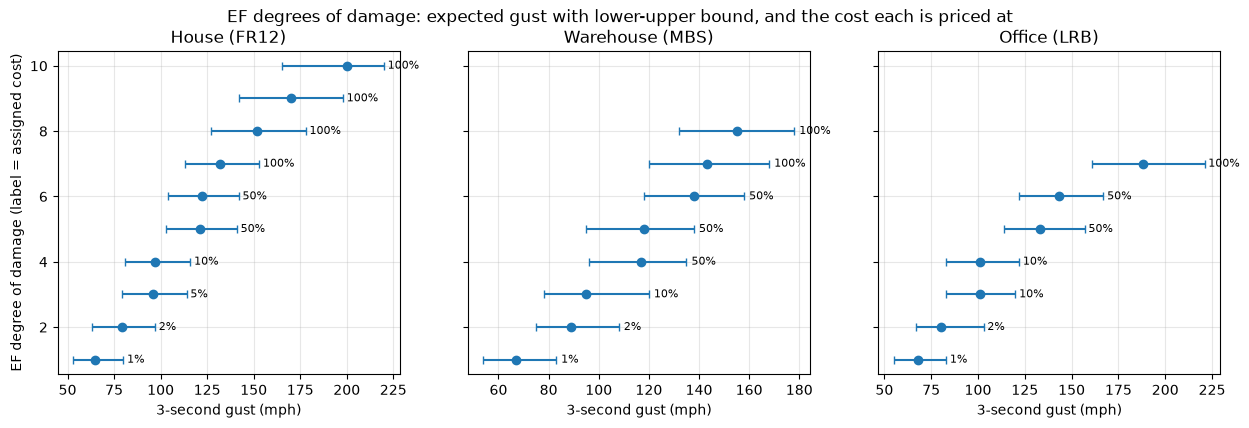

In [5]:
ef = table(f"EF_DEGREE_OF_DAMAGE_TABLE_{REG}.csv")
display(ef[["reference_building_id", "ef_damage_indicator", "dod", "damage_description", "expected_mph",
            "lower_bound_mph", "upper_bound_mph", "hazus_damage_state", "cost_ratio"]])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (b, g) in zip(axes, ef.groupby("reference_building_id", sort=False)):
    ax.errorbar(g["expected_mph"], g["dod"], xerr=[g["expected_mph"] - g["lower_bound_mph"], g["upper_bound_mph"] - g["expected_mph"]],
                fmt="o", capsize=3)
    for _, r in g.iterrows():
        ax.annotate(f'{r.cost_ratio:.0%}', (r.upper_bound_mph + 2, r.dod), fontsize=8, va="center")
    ax.set_title(f'{NAMES[b]} ({g["ef_damage_indicator"].iloc[0]})')
    ax.set_xlabel("3-second gust (mph)")
axes[0].set_ylabel("EF degree of damage (label = assigned cost)")
fig.suptitle("EF degrees of damage: expected gust with lower-upper bound, and the cost each is priced at")
save(fig, "00_ef_degrees_of_damage.png")
plt.show()

## 5. From degrees of damage to a curve

The gust that causes each degree varies between buildings of the same type. Reading the lower-upper bound as a 90%
range of a lognormal gives a spread β for each degree, and the expected repair cost at gust v is

```text
DR(v) = Σᵢ (cᵢ − cᵢ₋₁) · Φ( ln(v / EXPᵢ) / βᵢ ),   βᵢ = ln(UBᵢ / LBᵢ) / (2 × 1.645)
```

The derive script tabulates this every 1 mph from 0 to 255 mph. Below, the notebook recomputes the expression
with the derive module and compares it with the artifact's knots.

In [6]:
tab = derive.dod_table()
check = []
for p in ART["pathways"]:
    for r in p["curve_records"]:
        b = r["selector_match"]["reference_building_id"]
        f = derive.curve(tab[b], p["pathway_id"])
        diff = max(abs(round(f(float(x)), 6) - y) for x, y in r["parameters"]["points"])
        check.append({"curve_id": r["curve_id"], "knots": len(r["parameters"]["points"]), "max |recomputed - artifact|": diff})
display(pd.DataFrame(check))

,curve_id,knots,max |recomputed - artifact|
0,CWRE_RES_EF_FR12_STRAIGHT_LINE_ONSET96,256,0.0
1,CWRE_IND_EF_MBS_STRAIGHT_LINE_ONSET96,256,0.0
2,CWRE_OFF_EF_LRB_STRAIGHT_LINE_ONSET96,256,0.0
3,CWRE_RES_EF_FR12_TORNADO,256,0.0
4,CWRE_IND_EF_MBS_TORNADO,256,0.0
5,CWRE_OFF_EF_LRB_TORNADO,256,0.0


## 6. Straight-line wind starts at 96 mph

Tornado records use the EF expression directly. Straight-line records subtract the damage at 96 mph and rescale:
`DR_SL(v) = max(0, (DR(v) − DR(96)) / (1 − DR(96)))`. Without this, frequent ordinary storm gusts (Hazard counts a
58+ mph gust about every 1.5 years in a typical cell) add up to yearly losses hundreds of times FEMA's National Risk
Index. 96 mph is 90% of the typical ASCE 700-year design gust (107 mph).

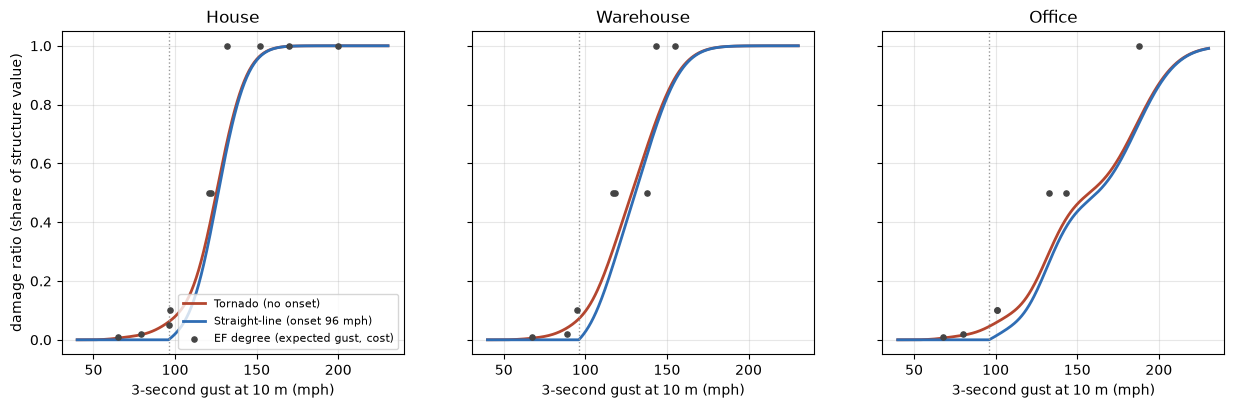

**NRI check** (median grid cell, % of building value per year; a check, not a calibration):

,reference_building_id,pathway_id,variant,ours_median_pct_per_year,nri_median_pct_per_year,ours_over_nri_median,spearman_rank_corr
0,RE_RES_SFD_1S_SLAB,straight_line_convective,proposal: onset 96 mph,0.02949,0.00110,27.04,0.526
1,RE_RES_SFD_1S_SLAB,straight_line_convective,no onset (tornado record shape),0.53731,0.00110,499.61,0.411
2,RE_RES_SFD_1S_SLAB,straight_line_convective,onset at 90% of the cell's ASCE 700-year gust,0.02875,0.00110,29.42,0.508
3,RE_RES_SFD_1S_SLAB,tornado_direct_hit,proposal,0.00063,0.00357,0.17,0.914
4,RE_IND_WAREHOUSE,straight_line_convective,proposal: onset 96 mph,0.03721,0.00110,34.57,0.532
5,RE_IND_WAREHOUSE,straight_line_convective,no onset (tornado record shape),0.48807,0.00110,452.72,0.426
6,RE_IND_WAREHOUSE,straight_line_convective,onset at 90% of the cell's ASCE 700-year gust,0.03628,0.00110,35.72,0.517
7,RE_IND_WAREHOUSE,tornado_direct_hit,proposal,0.00094,0.00357,0.26,0.914
8,RE_COM_OFFICE_3S_SLAB,straight_line_convective,proposal: onset 96 mph,0.01388,0.00110,13.10,0.529
9,RE_COM_OFFICE_3S_SLAB,straight_line_convective,no onset (tornado record shape),0.39995,0.00110,371.28,0.409


In [7]:
v = np.arange(40, 231, 0.5)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, b in zip(axes, NAMES):
    if b not in tab:
        continue
    ax.plot(v, [derive.curve(tab[b], "tornado_direct_hit")(x) for x in v], color="#b4462f", lw=2, label="Tornado (no onset)")
    ax.plot(v, [derive.curve(tab[b], "straight_line_convective")(x) for x in v], color="#2f6db4", lw=2, label="Straight-line (onset 96 mph)")
    g = ef[ef.reference_building_id == b]
    ax.scatter(g["expected_mph"], g["cost_ratio"], color="#444", s=14, zorder=3, label="EF degree (expected gust, cost)")
    ax.axvline(derive.ONSET_MPH, color="#999", ls=":", lw=1)
    ax.set_title(NAMES[b])
    ax.set_xlabel("3-second gust at 10 m (mph)")
axes[0].set_ylabel("damage ratio (share of structure value)")
axes[0].legend(fontsize=8, loc="lower right")
save(fig, "00_curves_from_degrees_of_damage.png")
plt.show()

nri = table(f"NRI_CHECK_{REG}.csv")
display(Markdown("**NRI check** (median grid cell, % of building value per year; a check, not a calibration):"))
display(nri[["reference_building_id", "pathway_id", "variant", "ours_median_pct_per_year", "nri_median_pct_per_year",
             "ours_over_nri_median", "spearman_rank_corr"]])

## 7. Sensitivity

How the damage ratio moves under the main alternative readings (spread, light-damage costs, the house foundation-shift state, onset).

In [8]:
sens = table(f"SENSITIVITY_{REG}.csv")
display(sens)

,reference_building_id,pathway_id,variant,role,dr_80mph,dr_100mph,dr_120mph,dr_140mph,dr_160mph
0,RE_RES_SFD_1S_SLAB,straight_line_convective,reference,reference,0.0000,0.0198,0.3180,0.8339,0.9895
1,RE_RES_SFD_1S_SLAB,straight_line_convective,bounds read as +/-1 sigma (68% range),spread_reading,0.0000,0.0358,0.3538,0.7278,0.9268
2,RE_RES_SFD_1S_SLAB,straight_line_convective,bounds read as +/-1.96 sigma (95% range),spread_reading,0.0000,0.0179,0.2962,0.8669,0.9965
3,RE_RES_SFD_1S_SLAB,straight_line_convective,light-damage costs (5% or less) x0.5,cost_assumption,0.0000,0.0212,0.3218,0.8348,0.9896
4,RE_RES_SFD_1S_SLAB,straight_line_convective,light-damage costs (5% or less) x2,cost_assumption,0.0000,0.0171,0.3105,0.8319,0.9894
5,RE_RES_SFD_1S_SLAB,straight_line_convective,house shifted off foundation = complete (100%),cost_assumption,0.0000,0.0275,0.4836,0.9391,0.9984
6,RE_RES_SFD_1S_SLAB,straight_line_convective,straight-line onset 90 mph,onset,0.0000,0.0414,0.3330,0.8375,0.9897
7,RE_RES_SFD_1S_SLAB,straight_line_convective,straight-line onset 100 mph,onset,0.0000,0.0000,0.3043,0.8305,0.9893
8,RE_RES_SFD_1S_SLAB,straight_line_convective,no straight-line onset,onset,0.0184,0.0792,0.3594,0.8439,0.9901
9,RE_RES_SFD_1S_SLAB,tornado_direct_hit,reference,reference,0.0184,0.0792,0.3594,0.8439,0.9901


## 8. Decisions

Every choice is a decision-log row. `JL decided` rows are owner choices; `proposed` rows are routine scope and contract choices awaiting the reviewer.

In [9]:
log = decision_log(PROP / f"DECISION_LOG_{REG}.md")
display(log.groupby("status").size().rename("decisions").to_frame())
display(log)

,decisions
status,
JL decided,5
proposed,11


,id,status,decision
0,D-CWRE-01,proposed,"One cell, `convective_wind_real_estate`, for the three Hazard reference profiles r1 (house `RE_RES_SFD_1S_SLAB`, warehouse `RE_IND_WAREHOUSE`, office `RE_CO..."
1,D-CWRE-02,proposed,Two governed pathways with the repository's existing IDs: `straight_line_convective` and `tornado_direct_hit`. Each has its own axis field (`convective_gust...
2,D-CWRE-03,JL decided,"JL decided — convective-specific evidence: the EF scale degrees of damage, not the hurricane building curves. Hurricane-curve reuse (as in the repository's ..."
3,D-CWRE-04,proposed,"Damage indicators: house = FR12 (one- and two-family residences), warehouse = MBS (metal building systems), office = LRB (low-rise building, 1–4 storeys)."
4,D-CWRE-05,proposed,"Axis = 3-second gust at 10 m in open terrain, mph, as Hazard delivers it, on both pathways. No terrain, height or averaging bridge in Damage. The EF speeds ..."
5,D-CWRE-06,proposed,Curve form: expected cost over the ordered degrees of damage. Each degree's causing gust is lognormal with median = expected speed and β = ln(UB/LB)/(2·1.64...
6,D-CWRE-07,JL decided,"JL decided — FEMA damage-state costs. Slight 2%, Moderate 10%, Extensive 50%, Complete 100% (Hazus 7.0 Hurricane TM §8.1.4.3), with each EF degree assigned ..."
7,D-CWRE-08,JL decided,"JL decided (2026-10-19). Tornado records use the EF curve directly, with no onset. Tornado-specific effects (pressure drop, rotation, debris) are inside the..."
8,D-CWRE-09,JL decided,"JL decided — straight-line onset at a fixed 96 mph: DR_SL(v) = max(0, (DR(v) − DR(96)) / (1 − DR(96))), so damage is zero at or below 96 mph and nearly unch..."
9,D-CWRE-10,proposed,The straight-line records are labelled a T4 transfer of tornado-derived EF evidence.


## 9. Parameter tiers

T2 = standard or physics; T3 = engineering proxy or expert elicitation; T4 = our judgment.

In [10]:
tiers = pd.DataFrame(ART["parameter_tier_table"])
cols = [c for c in ("parameter", "curve_id", "value", "tier", "status") if c in tiers.columns]
display(tiers[cols])
display(tiers.groupby("tier").size().rename("parameters").to_frame())

,parameter,curve_id,value,tier,status
0,axis_definition,all,"3-second gust at 10 m, open terrain (ASCE Exposure C), mph",T4_placeholder_or_expert_judgment,proposed
1,tornado_gust_bridge,CWRE_*_TORNADO,EF band midpoint gust accepted as the tornado gust,T4_placeholder_or_expert_judgment,proposed
2,dod_speeds_house,CWRE_RES_EF_FR12_*,"FR12 EXP/LB/UB, 10 degrees",T3_engineering_proxy_or_adjacent_empirical,proposed
3,dod_speeds_warehouse,CWRE_IND_EF_MBS_*,"MBS EXP/LB/UB, 8 degrees",T3_engineering_proxy_or_adjacent_empirical,proposed
4,dod_speeds_office,CWRE_OFF_EF_LRB_*,"LRB EXP/LB/UB, 7 degrees",T3_engineering_proxy_or_adjacent_empirical,proposed
5,damage_state_costs,all,"Slight 2%, Moderate 10%, Extensive 50%, Complete 100%; 5% between Slight and Moderate",T3_engineering_proxy_or_adjacent_empirical,proposed
6,dod_to_state_assignment,all,per EF_DEGREE_OF_DAMAGE_TABLE (cost_basis column),T4_placeholder_or_expert_judgment,proposed
7,below_slight_cost,all,1% for 'threshold of visible damage',T4_placeholder_or_expert_judgment,proposed
8,house_foundation_shift_cost,CWRE_RES_EF_FR12_*,50% (Extensive); 100% as sensitivity,T4_placeholder_or_expert_judgment,proposed
9,lognormal_spread,all,beta_i = ln(UB_i/LB_i)/(2 x 1.645),T4_placeholder_or_expert_judgment,proposed


,parameters
tier,
T2_public_lab_standard_or_physics,2
T3_engineering_proxy_or_adjacent_empirical,4
T4_placeholder_or_expert_judgment,9


## 10. What is still open

- The EF speeds are expert estimates and the costs are our placement on FEMA's ladder; no repair-cost data by EF degree exist.
- Straight-line records transfer tornado-derived evidence (T4).
- Hazard-side items found by the NRI check: straight-line frequency below the ASCE 10-year gust, tornado path sizes, and ASCE coastal maps that include hurricane winds.

The promotion gate lists what must happen before canonical use:

In [11]:
cap = ART["capability_declaration"]
rows = []
for pc in cap["pathway_capabilities"]:
    rows.append({"pathway": pc["pathway_id"], "failure-unit DR": pc["failure_unit_scalar_dr"],
                 "scenario loss": pc["scenario_loss_given_value_basis"], "spread": pc["curve_intrinsic_spread"],
                 "withheld units": ", ".join(w["failure_unit_id"] for w in pc.get("withheld_failure_units", []))})
display(pd.DataFrame(rows))
print("Annual and tail metrics:", cap["consumer_annual_metrics"]["status_before_promotion"],
      "(owner:", cap["consumer_annual_metrics"]["computation_owner"] + ")")
print("Promotion gate:", cap["promotion_gate"]["status"])
for item in cap["promotion_gate"]["required_before_canonical_use"]:
    print("  -", item)

,pathway,failure-unit DR,scenario loss,spread,withheld units
0,straight_line_convective,conditional,withheld,not_carried,CWRE_BUILDING_CONTENTS
1,tornado_direct_hit,conditional,withheld,not_carried,CWRE_BUILDING_CONTENTS


Annual and tail metrics: withheld_noncanonical_proposal (owner: downstream_consumer)
Promotion gate: blocked
  - owner accepts D-CWRE-01 to D-CWRE-16
  - consumer value qualification of each reference budget (shared with flood_real_estate)
  - reviewer accepts the T4 straight-line transfer and the cost assignment
  - independent review of the package
